# 01 - Data Understanding / EDA

**Projecto:** IA aplicada a Cyber - classificação de actividades de cibersegurança como *Normal* ou *Suspicious*.

**Dataset:** Cybercrime Forensic Dataset (Kaggle, `jimohyusuf/cybercrime-forensic-dataset`), com 7.400 observações e 11 variáveis, de 12/09/2024 a 12/10/2024.

A fonte no Kaggle confirma observações simuladas; ver [proveniência](../docs/dados.md). Não está demonstrada a independência das variáveis.

**Variável a prever:** `Label` (Normal / Suspicious).

**Objectivo deste notebook:** conhecer os dados antes de os preparar e de treinar modelos (qualidade dos dados, valores em falta, distribuições, relações com o `Label` e possível *data leakage*).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# keep_default_na=False: "None" (sem anomalia) e "N/A" são categorias reais, não valores em falta
df = pd.read_csv("../data/raw/cybercrime_forensic_dataset.csv",
                 keep_default_na=False, na_values=[""])
print(df.shape)
df.head()

(7400, 11)


,Timestamp,User_ID,IP_Address,Activity_Type,Resource_Accessed,File_Name,Action,Login_Attempts,File_Size,Anomaly_Type,Label
0,2024-09-27 12:53:26.390859,9288,10.174.236.5,File_Modification,/network/logs/new_project.docx,new_project.docx,Delete,NaN,30.66,DDoS_Attempt,Suspicious
1,2024-10-02 15:13:49.741543,1605,172.19.128.216,USB_Insert,/server/secrets.txt,NaN,Read,NaN,NaN,Brute_Force,Suspicious
2,2024-09-13 14:31:39.163288,3056,192.168.201.132,File_Modification,/project/document2.docx,document2.docx,N/A,NaN,21.61,DDoS_Attempt,Suspicious
3,2024-10-02 22:27:57.622008,1564,10.119.122.121,Network_Traffic,/backup/document2.docx,NaN,Delete,NaN,NaN,None,Normal
4,2024-10-01 08:00:55.017797,3660,172.23.2.38,USB_Insert,/confidential/report1.pdf,NaN,Write,NaN,NaN,None,Normal


## 1. Inspecção geral

In [2]:
df.info()
display(df.isnull().sum())
display((df.isnull().mean() * 100).round(1))
display(df.nunique())
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 7400 entries, 0 to 7399
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Timestamp          7400 non-null   str    
 1   User_ID            7400 non-null   int64  
 2   IP_Address         7400 non-null   str    
 3   Activity_Type      7400 non-null   str    
 4   Resource_Accessed  7400 non-null   str    
 5   File_Name          3196 non-null   str    
 6   Action             7400 non-null   str    
 7   Login_Attempts     2105 non-null   float64
 8   File_Size          3196 non-null   float64
 9   Anomaly_Type       7400 non-null   str    
 10  Label              7400 non-null   str    
dtypes: float64(2), int64(1), str(8)
memory usage: 636.1 KB


Timestamp               0
User_ID                 0
IP_Address              0
Activity_Type           0
Resource_Accessed       0
File_Name            4204
Action                  0
Login_Attempts       5295
File_Size            4204
Anomaly_Type            0
Label                   0
dtype: int64

Timestamp             0.0
User_ID               0.0
IP_Address            0.0
Activity_Type         0.0
Resource_Accessed     0.0
File_Name            56.8
Action                0.0
Login_Attempts       71.6
File_Size            56.8
Anomaly_Type          0.0
Label                 0.0
dtype: float64

Timestamp            7400
User_ID              5031
IP_Address           7353
Activity_Type           7
Resource_Accessed      36
File_Name               6
Action                  7
Login_Attempts         10
File_Size            2382
Anomaly_Type            5
Label                   2
dtype: int64

,User_ID,Login_Attempts,File_Size
count,7400.000000,2105.000000,3196.000000
mean,5535.768378,5.428504,24.669703
std,2575.574425,2.862625,14.133492
min,1000.000000,1.000000,0.130000
25%,3358.750000,3.000000,12.635000
50%,5516.000000,5.000000,24.590000
75%,7755.000000,8.000000,36.782500
max,9997.000000,10.000000,49.980000


In [3]:
# Verificações explícitas, mantendo o CSV original intacto.
duplicados = int(df.duplicated().sum())
print("Registos integralmente duplicados:", duplicados)
assert duplicados == 0
resumo_outliers = []
for coluna in ["Login_Attempts", "File_Size"]:
    valores = df[coluna].dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    resumo_outliers.append({"Variável": coluna, "Q1": q1, "Q3": q3,
                            "Limite inferior": inferior, "Limite superior": superior,
                            "Outliers (1,5 × IQR)": int(((valores < inferior) | (valores > superior)).sum())})
display(pd.DataFrame(resumo_outliers))
assert ((df["Anomaly_Type"] != "None") == (df["Label"] == "Suspicious")).all()
print("Correspondência entre Anomaly_Type e Label verificada em todos os registos.")


Registos integralmente duplicados: 0


,Variável,Q1,Q3,Limite inferior,Limite superior,"Outliers (1,5 × IQR)"
0,Login_Attempts,3.000,8.0000,-4.50000,15.50000,0
1,File_Size,12.635,36.7825,-23.58625,73.00375,0


Correspondência entre Anomaly_Type e Label verificada em todos os registos.


**Interpretação**

- 7.400 registos e 11 colunas, sem duplicados.
- `File_Name` e `File_Size` têm 4.204 valores em falta (56,8%) e `Login_Attempts` tem 5.295 (71,6%). Nas restantes colunas não há valores em falta.
- `IP_Address` (7.353 valores únicos) e `User_ID` (5.031) comportam-se como identificadores. `Timestamp` é único em todos os registos, mas permite extrair a hora e o dia da semana.
- `Login_Attempts` varia entre 1 e 10 e `File_Size` entre 0,13 e 49,98, com média e mediana próximas. Os histogramas sugerem distribuições aproximadamente uniformes. A tabela anterior explicita o critério de 1,5 × IQR, sem outliers numéricos identificados; isso não exclui anomalias de contexto.

## 2. Variável alvo e data leakage

In [4]:
display(df["Label"].value_counts())
display((df["Label"].value_counts(normalize=True) * 100).round(1))
display(pd.crosstab(df["Anomaly_Type"], df["Label"]))

Label
Normal        6167
Suspicious    1233
Name: count, dtype: int64

Label
Normal        83.3
Suspicious    16.7
Name: proportion, dtype: float64

Label,Normal,Suspicious
Anomaly_Type,,
Brute_Force,0,308
DDoS_Attempt,0,282
Data_Exfil,0,346
None,6167,0
USB_Access,0,297


**Interpretação**

- As classes estão desequilibradas: 6.167 Normal (83,3%) e 1.233 Suspicious (16,7%). Um modelo que diga sempre "Normal" teria 83,3% de accuracy sem detectar nada, pelo que a accuracy será secundária, acompanhada de Precision, Recall e F1 de Suspicious, matriz de confusão, ROC-AUC e Average Precision.
- `Anomaly_Type` determina perfeitamente o `Label`: "None" aparece sempre em Normal e as outras quatro anomalias (Brute_Force, DDoS_Attempt, Data_Exfil, USB_Access) aparecem sempre em Suspicious. Será excluída das entradas por revelar o alvo. Label_bin, criada adiante, também representa o alvo e nunca será uma entrada.

## 3. Valores em falta

In [5]:
display(pd.crosstab(df["Activity_Type"], df["Login_Attempts"].isnull(), colnames=["Login_Attempts nulo"]))
display(pd.crosstab(df["Activity_Type"], df["File_Size"].isnull(), colnames=["File_Size nulo"]))
display(pd.crosstab(df["Activity_Type"], df["File_Name"].isnull(), colnames=["File_Name nulo"]))

Login_Attempts nulo,False,True
Activity_Type,,
File_Access,0,1092
File_Deletion,0,1037
File_Modification,0,1067
Login,1053,0
Network_Traffic,0,1068
Remote_Login,1052,0
USB_Insert,0,1031


File_Size nulo,False,True
Activity_Type,,
File_Access,1092,0
File_Deletion,1037,0
File_Modification,1067,0
Login,0,1053
Network_Traffic,0,1068
Remote_Login,0,1052
USB_Insert,0,1031


File_Name nulo,False,True
Activity_Type,,
File_Access,1092,0
File_Deletion,1037,0
File_Modification,1067,0
Login,0,1053
Network_Traffic,0,1068
Remote_Login,0,1052
USB_Insert,0,1031


**Interpretação**
Os valores em falta são estruturais e dependem do tipo de atividade:
- Login_Attempts existe apenas em Login e Remote_Login.
- File_Size e File_Name existem em File_Access, File_Deletion e File_Modification.
Não se apagam estas linhas por ausência estrutural. Zero pode representar números não aplicáveis, mantendo Activity_Type. Um número desconhecido numa atividade aplicável será distinguido e recusado na preparação. Para File_Name, se utilizado, Not_Applicable é mais explícito do que zero; a sua exclusão por redundância será justificada.


## 4. Análise univariada

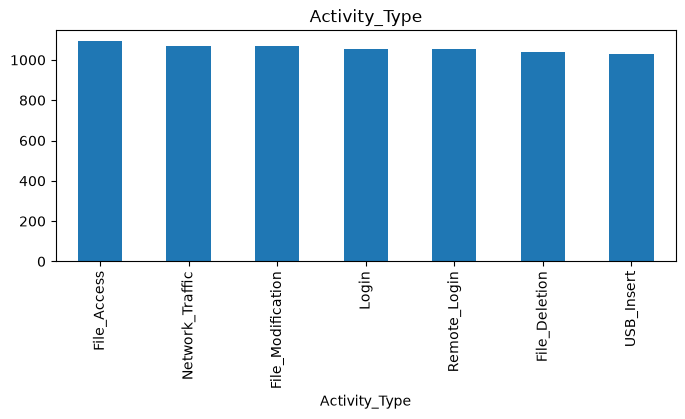

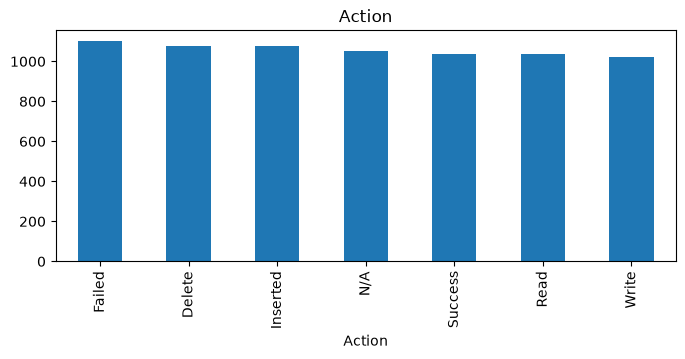

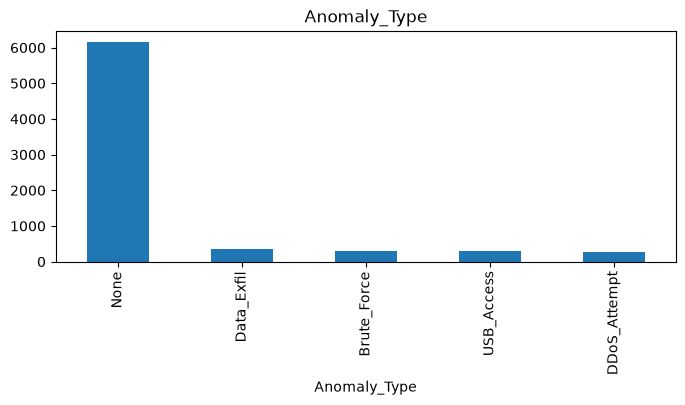

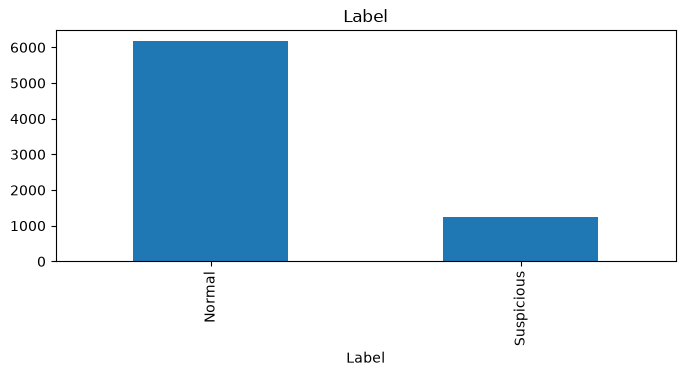

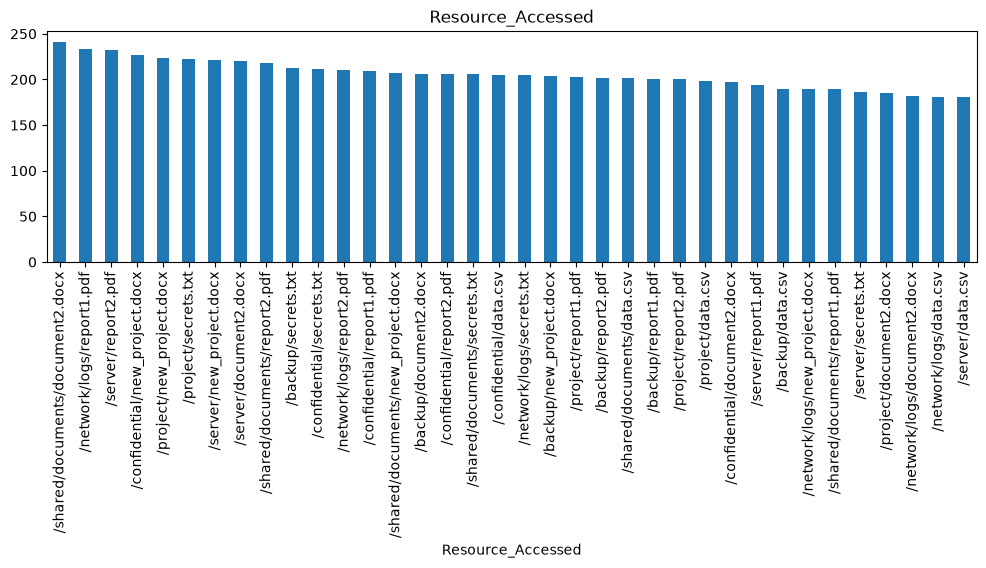

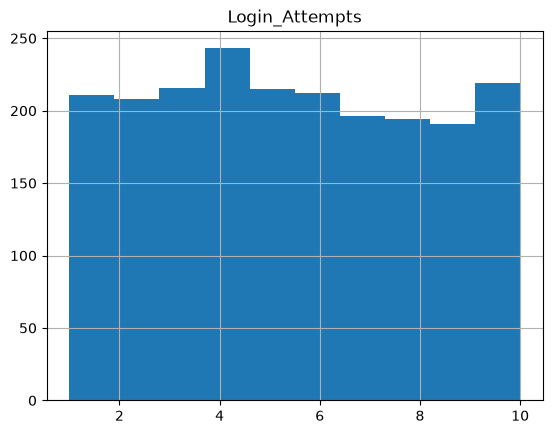

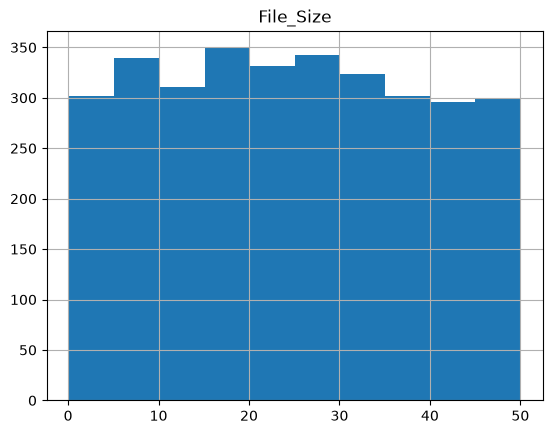

In [6]:
for col in ["Activity_Type", "Action", "Anomaly_Type", "Label"]:
    df[col].value_counts().plot(kind="bar", title=col, figsize=(8, 3))
    plt.show()

df["Resource_Accessed"].value_counts().plot(kind="bar", title="Resource_Accessed", figsize=(12, 3))
plt.show()

df["Login_Attempts"].hist()
plt.title("Login_Attempts")
plt.show()

df["File_Size"].hist()
plt.title("File_Size")
plt.show()

**Interpretação**

- `Activity_Type` e `Action` têm 7 categorias cada, com frequências muito parecidas (cerca de 14% cada). "N/A" em `Action` é uma categoria real.
- `Resource_Accessed` tem 36 caminhos, cada um com cerca de 180 a 240 registos, sem nenhum dominante.
- `Login_Attempts` (1 a 10) e `File_Size` (0 a 50) têm distribuições aproximadamente uniformes.
- Em conjunto com combinações pouco realistas (por exemplo, `Action = Delete` num `Login`), a análise levanta dúvidas sobre a representatividade das relações. A fonte confirma observações simuladas, mas a independência das variáveis não foi demonstrada.

## 5. Análise bivariada

A referência é a proporção global de Suspicious (16,7%).

In [7]:
df["Folder"] = df["Resource_Accessed"].str.split("/").str[1]

for col in ["Activity_Type", "Action", "Folder"]:
    display((pd.crosstab(df[col], df["Label"], normalize="index") * 100).round(1))

display(df.groupby("Label")[["Login_Attempts", "File_Size"]].describe().round(2))

Label,Normal,Suspicious
Activity_Type,,
File_Access,83.9,16.1
File_Deletion,85.0,15.0
File_Modification,82.2,17.8
Login,83.4,16.6
Network_Traffic,84.0,16.0
Remote_Login,84.2,15.8
USB_Insert,80.7,19.3


Label,Normal,Suspicious
Action,,
Delete,82.7,17.3
Failed,82.5,17.5
Inserted,84.7,15.3
N/A,83.5,16.5
Read,83.8,16.2
Success,84.2,15.8
Write,82.0,18.0


Label,Normal,Suspicious
Folder,,
backup,84.0,16.0
confidential,82.3,17.7
network,81.5,18.5
project,84.1,15.9
server,83.6,16.4
shared,84.5,15.5


Login_Attempts                                       File_Size  \
                    count  mean   std  min  25%  50%  75%   max     count   
Label                                                                       
Normal             1764.0  5.49  2.85  1.0  3.0  5.0  8.0  10.0    2674.0   
Suspicious          341.0  5.09  2.88  1.0  3.0  5.0  7.0  10.0     522.0   

                                                            
             mean    std   min    25%    50%    75%    max  
Label                                                       
Normal      24.74  14.16  0.15  12.80  24.69  36.68  49.98  
Suspicious  24.33  14.02  0.13  11.31  23.78  36.89  49.97

**Interpretação**

Em todas as variáveis, a percentagem de Suspicious por categoria fica entre cerca de 15% e 19%, perto dos 16,7% globais:

- `Activity_Type`: de 15,0% (`File_Deletion`) a 19,3% (`USB_Insert`).
- `Action`: de 15,3% (`Inserted`) a 18,0% (`Write`).
- `Folder`: de 15,5% (`shared`) a 18,5% (`network`).
- `Login_Attempts` e `File_Size` têm médias e medianas quase iguais nas duas classes.

Estas tabelas não mostram separação clara. A variabilidade amostral pode contribuir para as diferenças, mas não foi demonstrada independência nem excluída a existência de interações. Resource_Accessed e File_Name exigem uma decisão explícita sobre representação e redundância.

## 6. Correlação (Pearson e Spearman) e padrões temporais

,Login_Attempts,File_Size,Hour,DayOfWeek,Label_bin
Login_Attempts,1.000,NaN,0.048,-0.008,-0.052
File_Size,NaN,1.000,0.022,0.002,-0.011
Hour,0.048,0.022,1.000,-0.008,0.012
DayOfWeek,-0.008,0.002,-0.008,1.000,0.005
Label_bin,-0.052,-0.011,0.012,0.005,1.000


,Login_Attempts,File_Size,Hour,DayOfWeek,Label_bin
Login_Attempts,1.000,NaN,0.047,-0.010,-0.052
File_Size,NaN,1.000,0.023,0.002,-0.011
Hour,0.047,0.023,1.000,-0.009,0.013
DayOfWeek,-0.010,0.002,-0.009,1.000,0.005
Label_bin,-0.052,-0.011,0.013,0.005,1.000


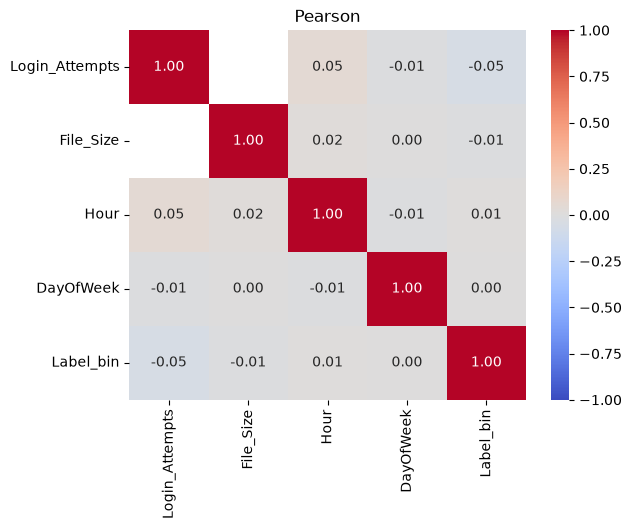

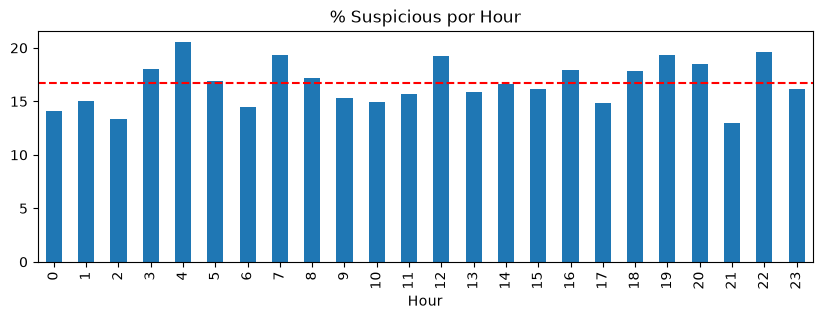

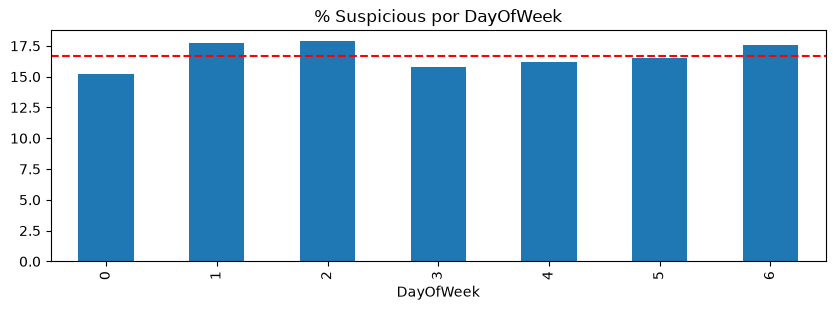

In [8]:
df["Label_bin"] = (df["Label"] == "Suspicious").astype(int)
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df["Hour"] = df["Timestamp"].dt.hour
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek

cols = ["Login_Attempts", "File_Size", "Hour", "DayOfWeek", "Label_bin"]
pear = df[cols].corr(method="pearson")
spear = df[cols].corr(method="spearman")
display(pear.round(3))
display(spear.round(3))

sns.heatmap(pear, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson")
plt.show()

for col in ["Hour", "DayOfWeek"]:
    (df.groupby(col)["Label_bin"].mean() * 100).plot(kind="bar", figsize=(10, 3), title=f"% Suspicious por {col}")
    plt.axhline(16.7, color="red", linestyle="--")
    plt.show()

**Interpretação**

- As correlações das variáveis numéricas com o `Label` estão entre -0,05 e 0,01 (Pearson e Spearman dão valores praticamente iguais): não há relação linear nem monótona relevante.
- A correlação entre `Login_Attempts` e `File_Size` é `NaN` porque nunca existem no mesmo registo (cada uma só existe em tipos de actividade diferentes).
- A percentagem de Suspicious por hora oscila entre cerca de 13% e 20,5%, e por dia da semana entre 15,2% e cerca de 18%, em torno dos 16,7%, sem padrão temporal claro nesta agregação. A variação pode incluir ruído amostral; não foi demonstrado que todas as oscilações resultem do acaso.

## 7. Análise multivariada

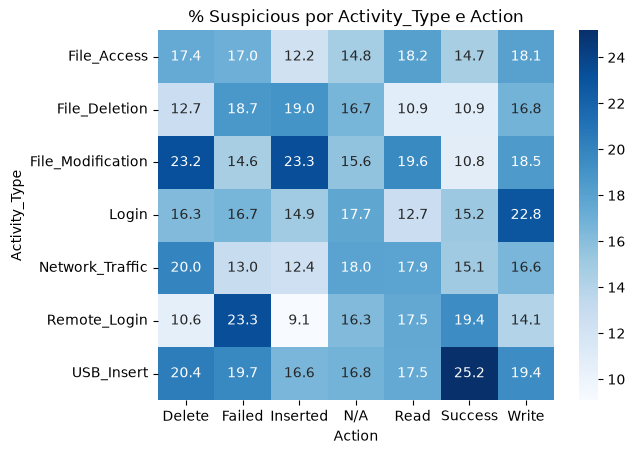

In [9]:
pivot = df.pivot_table(index="Activity_Type", columns="Action", values="Label_bin", aggfunc="mean") * 100
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues")
plt.title("% Suspicious por Activity_Type e Action")
plt.show()

**Interpretação**

As células vão de 9,1% a 25,2%, mas cada combinação tem apenas cerca de 150 registos, e com 49 células a variabilidade amostral e as múltiplas comparações devem ser consideradas. O gráfico não demonstra que todas as diferenças resultem do acaso. Algumas combinações não têm sentido real (por exemplo `USB_Insert` com `Success`), o que limita a interpretação operacional. A fonte confirma a origem simulada; o mecanismo de geração não é conhecido.

## Conclusões da EDA

1. 7 400 observações e 11 variáveis, sem duplicados completos.
2. Classes desequilibradas: 83,3% Normal e 16,7% Suspicious. Accuracy será secundária, acompanhada de Precision, Recall, F1, matriz de confusão, ROC-AUC e Average Precision.
3. Anomaly_Type determina perfeitamente Label e será excluída das entradas, tal como Label e Label_bin.
4. Os valores em falta em Login_Attempts, File_Size e File_Name dependem do tipo de atividade.
5. User_ID e IP_Address exigem análise do risco de memorização. Timestamp permite derivar contexto temporal sem usar o instante único como identificador.
6. Não foram identificados outliers numéricos pelo critério de 1,5 × IQR; isso não exclui anomalias de contexto.
7. As análises realizadas não identificaram separação clara das classes. Relações não lineares e capacidade de generalização serão avaliadas face a referências simples.
8. A EDA utilizou o dataset completo; o teste reservado posteriormente não é totalmente desconhecido desde o início.

**Próximo passo:** 02_data_preparation.ipynb.
